<a href="https://colab.research.google.com/github/govardhansnair/Monte-Carlo-Option-Pricing/blob/main/02_Monte_Carlo_Project_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Enter current stock price: 100
Enter strike price: 100
Enter time to expiry in years: 1
Enter risk-free interest rate (%): 0.05
Enter annual volatility (%): 0.20
MONTE CARLO OPTION PRICING
Initial Stock Price: 100.0
Strike Price: 100.0
Risk-Free Rate: 0.05
Volatility: 0.2
Time to Maturity: 1.0
Number of Simulations: 100000

SIMULATED STOCK PRICES
First 10 simulated prices:
[113.8080226  100.23498965 117.29684912 139.73896651  98.33101696
  98.33133983 141.31801116 120.1399282   93.81036104 114.85634743]

MONTE CARLO OPTION PRICES
European Call Price: 10.4739
European Put Price: 5.5742

STATISTICAL ACCURACY
Call Standard Error: 0.04659
Call 95% Confidence Interval: (np.float64(10.3826), np.float64(10.5652))
Put Standard Error: 0.02738
Put 95% Confidence Interval: (np.float64(5.5205), np.float64(5.6279))

MODEL COMPARISON
        Model  Call Price  Put Price
  Monte Carlo     10.4739     5.5742
Black-Scholes     10.4506     5.5735

ABSOLUTE PRICING ERRORS
Call Error: 0.02331
Put Error: 0

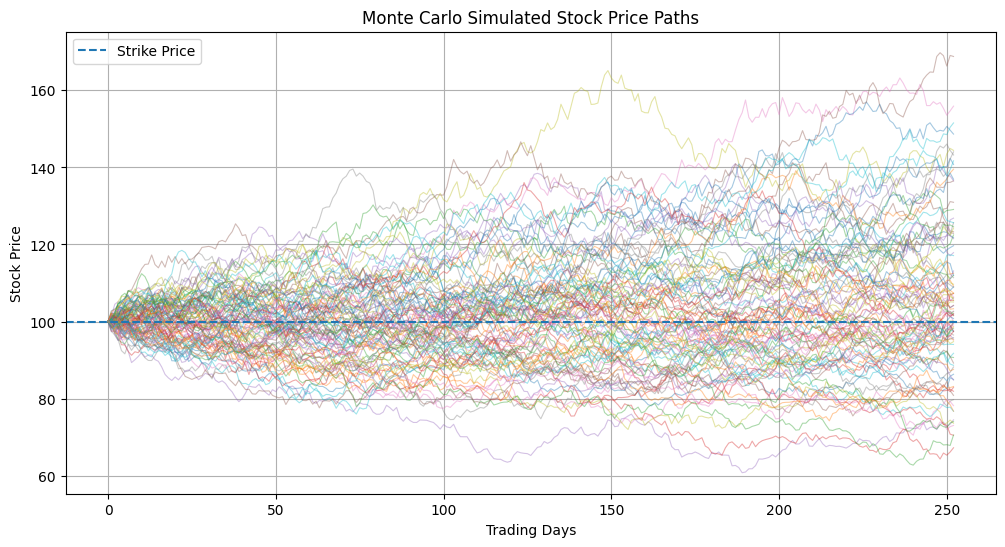

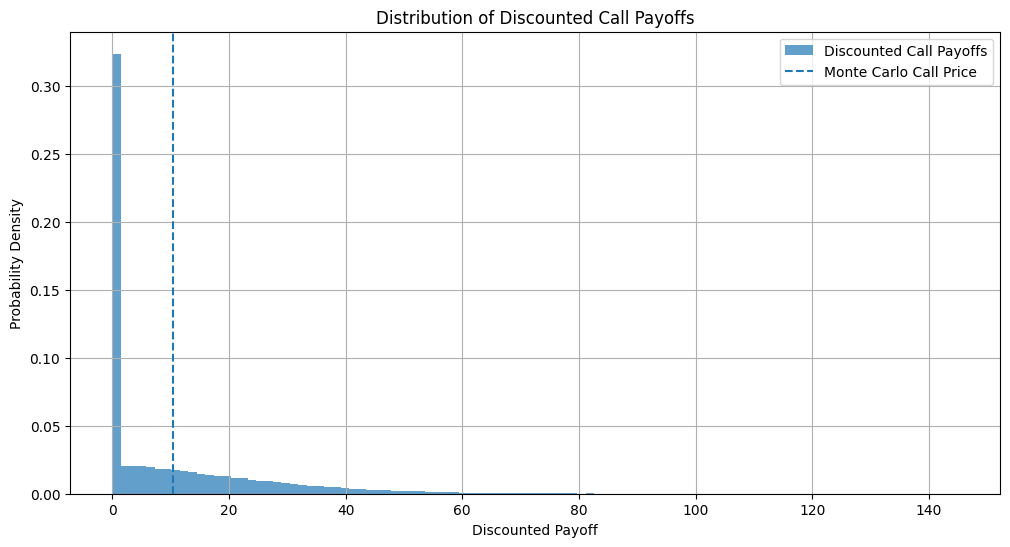

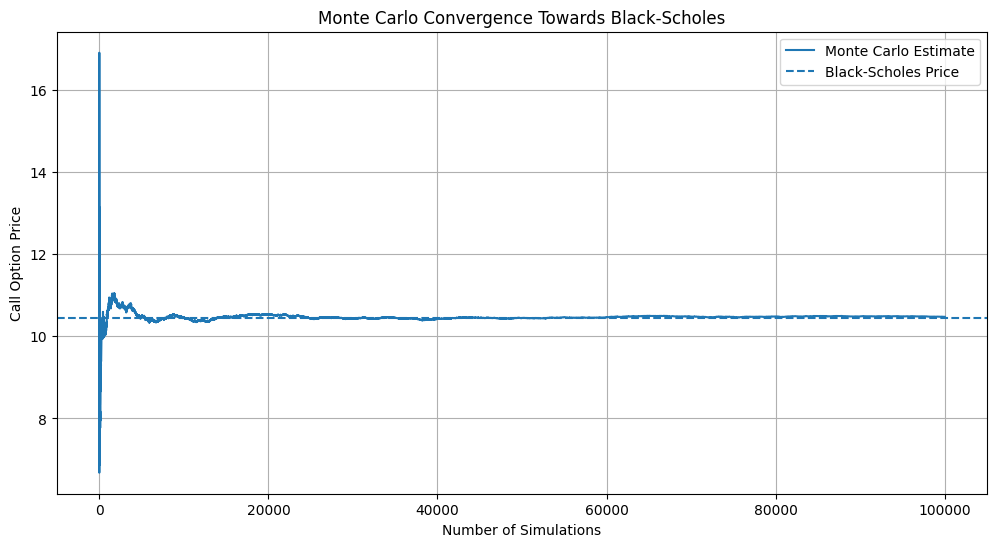


ANTITHETIC VARIATES
Standard Monte Carlo Price: 10.47389
Antithetic Monte Carlo Price: 10.44239
Standard MC Standard Error: 0.04659
Antithetic Standard Error: 0.03265
Antithetic 95% Confidence Interval: (np.float64(10.37839), np.float64(10.50639))

FINAL PROJECT RESULTS
                   Metric   Result
   Monte Carlo Call Price 10.47389
 Black-Scholes Call Price 10.45058
    Monte Carlo Put Price  5.57419
  Black-Scholes Put Price  5.57353
      Call Standard Error  0.04659
       Put Standard Error  0.02738
    Antithetic Call Price 10.44239
Antithetic Standard Error  0.03265


In [ ]:

# MONTE CARLO OPTION PRICING PROJECT
# European Call and Put Options

# IMPORT LIBRARIES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm


# DEFINE PARAMETERS

#S0=100          # Current stock price
#K=100           # Strike price
#r=0.05          # Risk-free interest rate (5%)
#sigma=0.20      # Volatility (20%)
#T=1.0           # Time to maturity (1 year)
#N=100000        # Number of simulations

S0 = float(input("Enter current stock price: "))
K = float(input("Enter strike price: "))
T = float(input("Enter time to expiry in years: "))
r = float(input("Enter risk-free interest rate (%): "))
sigma = float(input("Enter annual volatility (%): "))
N = 100000
np.random.seed(42)

# CHECK INPUTS

if S0 <= 0 or K <= 0 or T <= 0 or sigma <= 0:
  raise ValueError("Stock price, strike price, time and volatility must be positive.")

print("MONTE CARLO OPTION PRICING")
print("Initial Stock Price:", S0)
print("Strike Price:", K)
print("Risk-Free Rate:", r)
print("Volatility:", sigma)
print("Time to Maturity:", T)
print("Number of Simulations:", N)

# Generate normally distributed random numbers
Z=np.random.normal(0,1,N)


# 4. SIMULATE FUTURE STOCK PRICES USING GBM

# Risk-neutral GBM terminal stock price formula

ST=S0*np.exp((r-0.5*sigma**2)*T+sigma*np.sqrt(T)*Z)

print("\nSIMULATED STOCK PRICES")
print("First 10 simulated prices:")
print(ST[:10])

# OPTION PAYOFFS

# European Call Payoff
call_payoffs=np.maximum(ST-K,0)

# European Put Payoff
put_payoffs=np.maximum(K-ST,0)

# CALCULATE MONTE CARLO OPTION PRICES

discount_factor=np.exp(-r*T)

call_price_MC=discount_factor*np.mean(call_payoffs)
put_price_MC=discount_factor*np.mean(put_payoffs)

print("\nMONTE CARLO OPTION PRICES")
print("European Call Price:",round(call_price_MC, 4))
print("European Put Price:",round(put_price_MC, 4))

# CALCULATE STANDARD ERROR AND CONFIDENCE INTERVAL

# Discount individual payoffs

discounted_call=discount_factor*call_payoffs
discounted_put=discount_factor*put_payoffs

# Standard Error

call_SE=np.std(discounted_call,ddof=1)/np.sqrt(N)
put_SE=np.std(discounted_put,ddof=1)/np.sqrt(N)

# 95% Confidence Intervals

call_CI=(call_price_MC-1.96*call_SE,call_price_MC+1.96*call_SE)

put_CI=(put_price_MC-1.96*put_SE,put_price_MC+1.96*put_SE)

print("\nSTATISTICAL ACCURACY")

print("Call Standard Error:",round(call_SE, 5))
print("Call 95% Confidence Interval:",tuple(round(x, 4) for x in call_CI))

print("Put Standard Error:",round(put_SE, 5))
print("Put 95% Confidence Interval:",tuple(round(x, 4) for x in put_CI))


# BLACK-SCHOLES OPTION PRICING
d1=(np.log(S0 / K)+(r+0.5*sigma**2)*T)/(sigma*np.sqrt(T))

d2=d1-sigma*np.sqrt(T)

# Black-Scholes Call Price

call_BS=(S0*norm.cdf(d1)-K*np.exp(-r*T)*norm.cdf(d2))

# Black-Scholes Put Price

put_BS=(K*np.exp(-r*T)*norm.cdf(-d2)-S0*norm.cdf(-d1))

# COMPARE MONTE CARLO WITH BLACK-SCHOLES

comparison= pd.DataFrame({"Model":["Monte Carlo", "Black-Scholes"],"Call Price": [call_price_MC, call_BS],"Put Price": [put_price_MC, put_BS]})

print("\nMODEL COMPARISON")
print(comparison.round(4).to_string(index=False))

print("\nABSOLUTE PRICING ERRORS")
print("Call Error:", round(abs(call_price_MC - call_BS), 5))
print("Put Error:", round(abs(put_price_MC - put_BS), 5))


# MONTE CARLO PRICING FUNCTION

def monte_carlo_price(S, K, r, sigma, T, Z, option_type="call"):

  ST=S*np.exp((r-0.5*sigma**2)*T+sigma*np.sqrt(T)*Z)

  if option_type.lower() == "call":
    payoff = np.maximum(ST - K, 0)

  elif option_type.lower() == "put":
    payoff = np.maximum(K - ST, 0)

  else:
    raise ValueError("Option type must be call or put")

  return np.exp(-r * T) * np.mean(payoff)


# CALCULATE OPTION GREEKS

def monte_carlo_greeks(S, K, r, sigma, T, Z, option_type="call"):

    # Small changes in model parameters

    hS = 0.1
    hV = 0.001
    hT = 0.001
    hR = 0.0001

    # Original option price

    V0 = monte_carlo_price(S,K,r,sigma,T,Z,option_type)

    # Delta and Gamma

    V_up=monte_carlo_price(S+hS,K,r,sigma,T,Z,option_type    )

    V_down=monte_carlo_price(S-hS,K,r,sigma,T,Z,option_type)

    delta=(V_up-V_down)/(2*hS)

    gamma=(V_up-2*V0*V_down)/(hS**2)

    # Vega

    V_vol_up=monte_carlo_price(S,K,r,sigma+hV,T,Z,option_type)

    V_vol_down=monte_carlo_price(S,K,r,sigma-hV,T,Z,option_type)

    vega=(V_vol_up-V_vol_down)/(2*hV)

    # Theta
    # Negative derivative with respect to time to maturity

    V_time_up=monte_carlo_price(S,K,r,sigma,T+hT,Z,option_type)

    V_time_down=monte_carlo_price(S,K,r,sigma,T-hT,Z,option_type)

    theta=-(V_time_up-V_time_down)/(2*hT)

    # Rho

    V_rate_up = monte_carlo_price(S, K, r + hR, sigma, T, Z, option_type)

    V_rate_down = monte_carlo_price(S, K, r - hR, sigma, T, Z, option_type)

    rho = (V_rate_up - V_rate_down)/(2 * hR)

    return {
        "Price": V0,
        "Delta": delta,
        "Gamma": gamma,
        "Vega": vega,
        "Vega per 1%": vega / 100,
        "Theta": theta,
        "Rho": rho,
        "Rho per 1%": rho / 100
    }


# Calculate Greeks for Call and Put

call_greeks = monte_carlo_greeks(S0, K, r, sigma, T, Z, "call")

put_greeks = monte_carlo_greeks(S0, K, r, sigma, T, Z, "put")

print("\nCALL OPTION GREEKS")

for greek, value in call_greeks.items():
    print(greek + ":", round(value, 5))

print("\nPUT OPTION GREEKS")

for greek, value in put_greeks.items():
    print(greek + ":", round(value, 5))


# SIMULATE COMPLETE STOCK PRICE PATHS

steps = 252
paths = 100

dt = T / steps

Z_paths = np.random.normal(0, 1, (paths, steps))

stock_paths = np.zeros((paths, steps + 1))

stock_paths[:, 0] = S0

for t in range(steps):

    stock_paths[:, t + 1] = stock_paths[:, t] * np.exp((r - 0.5 * sigma**2) * dt
        + sigma * np.sqrt(dt) * Z_paths[:, t])


# Visualise stock price paths

plt.figure(figsize=(12, 6))

for i in range(paths):
    plt.plot(stock_paths[i], alpha=0.4, linewidth=0.8)

plt.axhline(K, linestyle="--", label="Strike Price")

plt.title("Monte Carlo Simulated Stock Price Paths")
plt.xlabel("Trading Days")
plt.ylabel("Stock Price")
plt.legend()
plt.grid(True)
plt.show()


# PAYOFF DISTRIBUTION

plt.figure(figsize=(12, 6))

plt.hist(
    discounted_call,
    bins=100,
    density=True,
    alpha=0.7,
    label="Discounted Call Payoffs"
)

plt.axvline(
    call_price_MC,
    linestyle="--",
    label="Monte Carlo Call Price"
)

plt.title("Distribution of Discounted Call Payoffs")
plt.xlabel("Discounted Payoff")
plt.ylabel("Probability Density")
plt.legend()
plt.grid(True)
plt.show()


# MONTE CARLO CONVERGENCE GRAPH
cumulative_payoffs = np.cumsum(discounted_call)

simulation_numbers = np.arange(1, N + 1)

running_prices = cumulative_payoffs / simulation_numbers

plt.figure(figsize=(12, 6))

plt.plot(
    simulation_numbers,
    running_prices,
    label="Monte Carlo Estimate"
)

plt.axhline(
    call_BS,
    linestyle="--",
    label="Black-Scholes Price"
)

plt.title("Monte Carlo Convergence Towards Black-Scholes")
plt.xlabel("Number of Simulations")
plt.ylabel("Call Option Price")
plt.legend()
plt.grid(True)
plt.show()

# ANTITHETIC VARIATES - VARIANCE REDUCTION

# Use half as many independent shocks.
# Each shock is paired with its negative.
# Total simulated terminal prices = N.

N_half = N // 2

Z_half = np.random.normal(0, 1, N_half)

ST_positive = S0 * np.exp((r - 0.5 * sigma**2) * T+ sigma * np.sqrt(T) * Z_half)

ST_negative = S0 * np.exp((r - 0.5 * sigma**2) * T- sigma * np.sqrt(T) * Z_half)

# Discounted payoffs for each pair

payoff_positive = discount_factor * np.maximum(ST_positive - K, 0)

payoff_negative = discount_factor * np.maximum(ST_negative - K, 0)

# Average each pair to create independent pair observations

pair_payoffs = 0.5 * (payoff_positive + payoff_negative)

# Antithetic Monte Carlo price

call_anti = np.mean(pair_payoffs)

# Correct standard error: based on independent pair averages

SE_anti = np.std(pair_payoffs, ddof=1) / np.sqrt(N_half)

CI_anti = (call_anti - 1.96 * SE_anti,call_anti + 1.96 * SE_anti)

print("\nANTITHETIC VARIATES")

print("Standard Monte Carlo Price:", round(call_price_MC, 5))
print("Antithetic Monte Carlo Price:", round(call_anti, 5))

print("Standard MC Standard Error:", round(call_SE, 5))
print("Antithetic Standard Error:", round(SE_anti, 5))

print("Antithetic 95% Confidence Interval:",
      tuple(round(x, 5) for x in CI_anti))


# FINAL PROJECT SUMMARY
summary = pd.DataFrame({
    "Metric": [
        "Monte Carlo Call Price",
        "Black-Scholes Call Price",
        "Monte Carlo Put Price",
        "Black-Scholes Put Price",
        "Call Standard Error",
        "Put Standard Error",
        "Antithetic Call Price",
        "Antithetic Standard Error"
    ],

    "Result": [
        call_price_MC,
        call_BS,
        put_price_MC,
        put_BS,
        call_SE,
        put_SE,
        call_anti,
        SE_anti
    ]
})

print("\nFINAL PROJECT RESULTS")
print(summary.round(5).to_string(index=False))
